# 92 — Gateway e Policy em cada conta

Referência: [AgentCore workshops](https://github.com/awslabs/agentcore-samples/tree/main/06-workshops). Esta aula conserva o código da arquitetura anterior enquanto sua conversão está pendente.

**Bloco final multiconta — fora da jornada de conta única do Workshop Studio.** Anteriormente aula 12; o ID `12` nas chamadas e evidências legadas permanece estável. A mudança de ordem não altera os recursos nem dispensa as quatro contas.

## Arquitetura desta aula

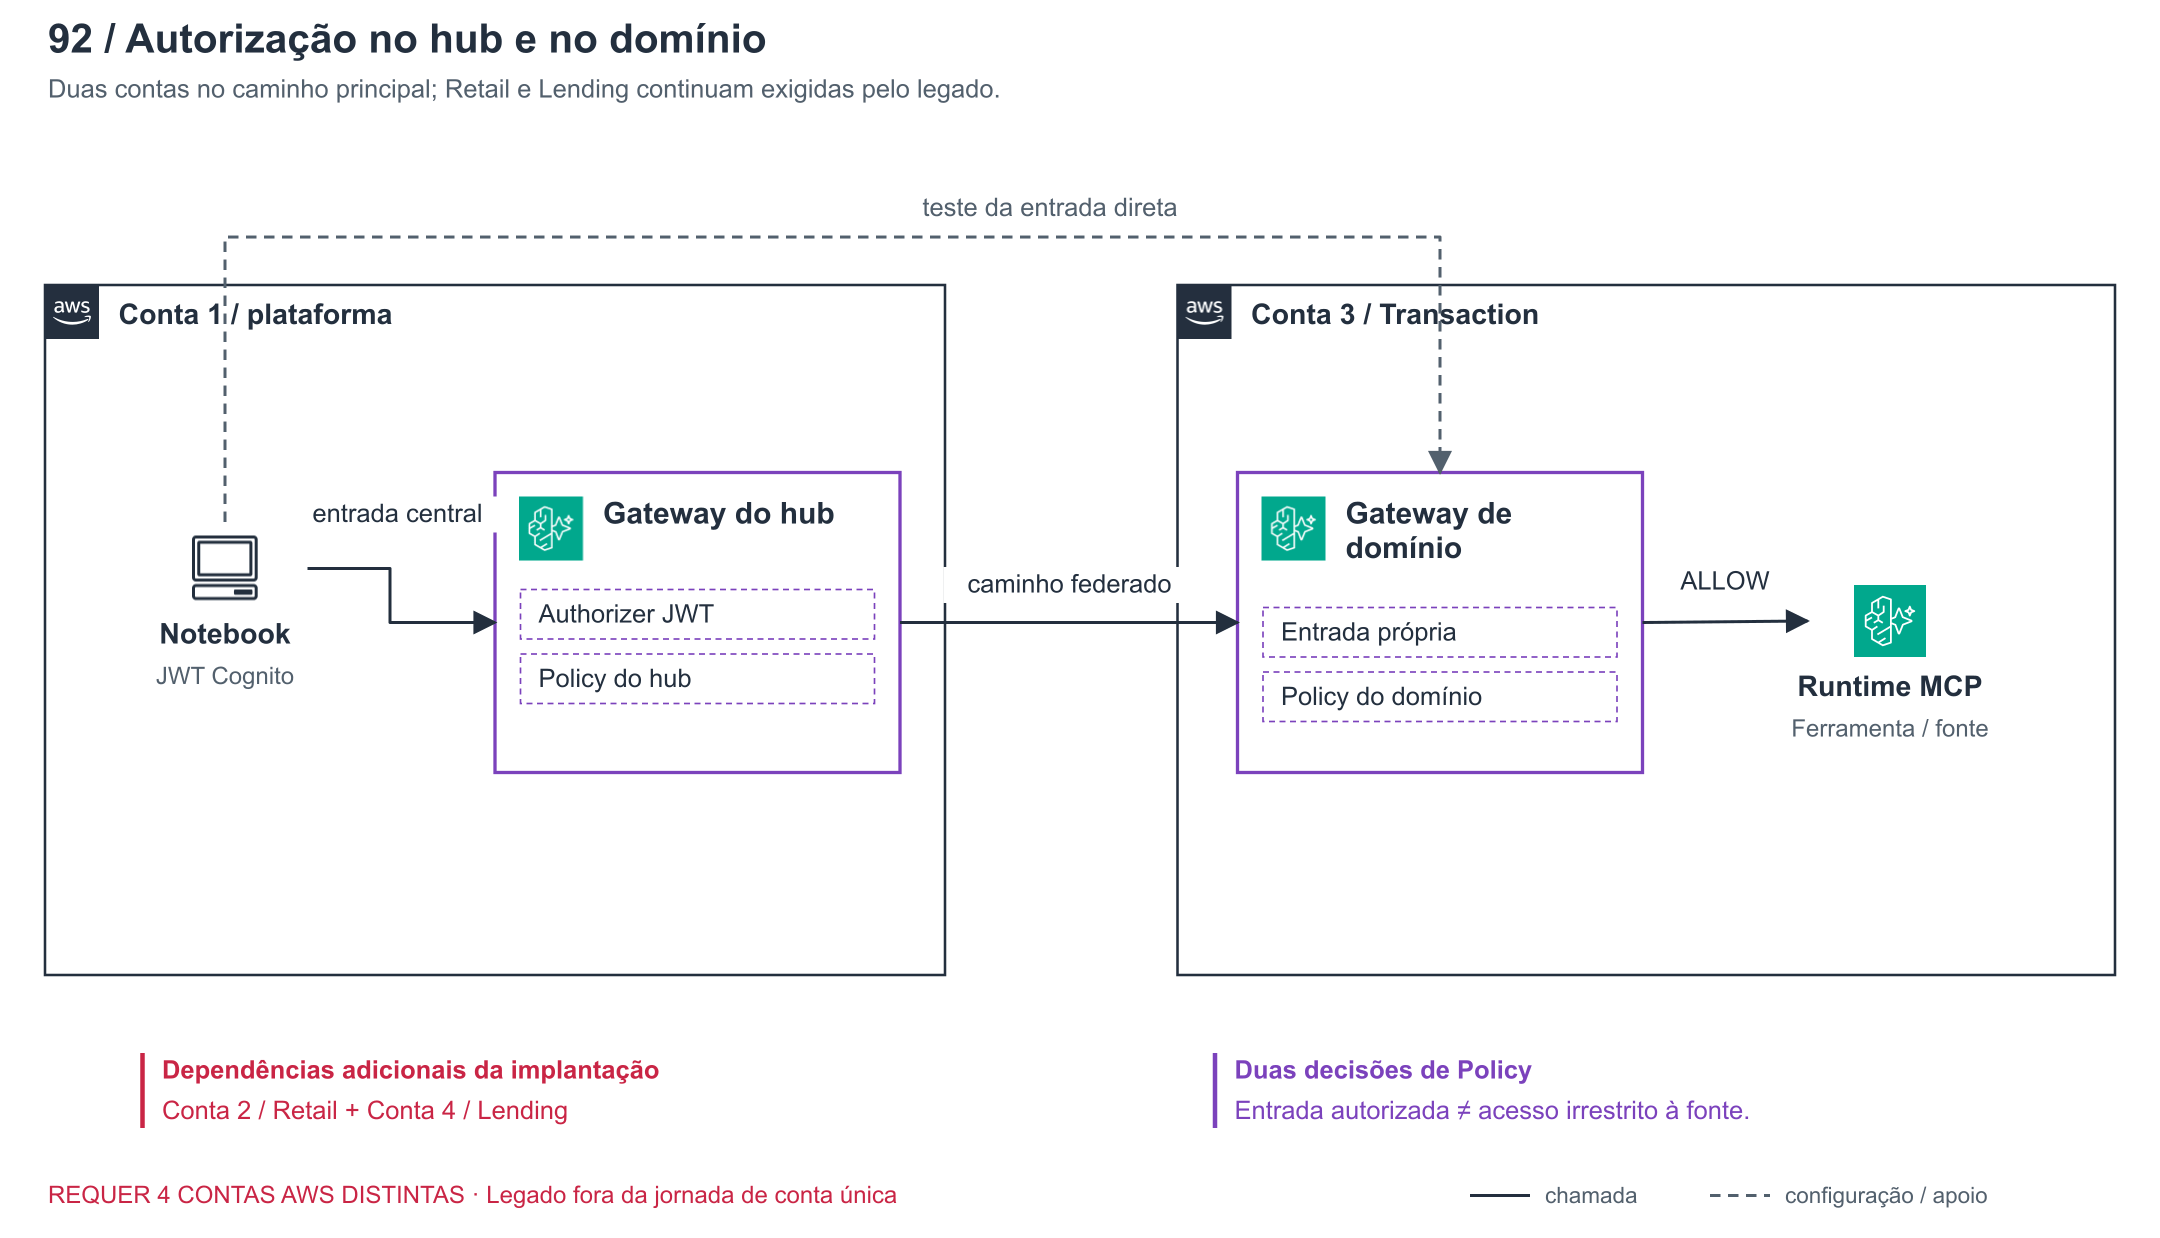

**Como ler o desenho:** Há dois pontos de controle visíveis: a entrada no hub e a entrada direta do domínio. O diagrama mostra duas contas ativas no fluxo e as outras duas exigidas pela configuração legada.

[Abrir PNG](../docs/diagramas/aulas/92.png) · [Abrir SVG](../docs/diagramas/aulas/92.svg)

## O que você vai aprender

**Pergunta da aula:** Uma entrada central elimina a necessidade de autorização na conta de destino?

1. Comparar Gateway e Policy da plataforma e da conta Transaction.
2. Testar a negativa nas duas entradas.

**Estudo do legado — quatro contas AWS distintas.** Esta aula ainda depende da implantação anterior e não foi validada na jornada SDK atual. Não execute este notebook na conta única do Workshop Studio.

**Antes de começar:** Legado: quatro contas preparadas; o fluxo ilustrado destaca plataforma e Transaction.

**O que esta aula cria ou remove:** Nenhum recurso; consulta as configurações e exerce chamadas existentes.

**O que reutiliza:** Gateways, engines e identidades da implantação anterior.

## Serviços AWS e suas responsabilidades

| Serviço | O que ele faz | Papel nesta aula |
|---|---|---|
| **Amazon Bedrock AgentCore Gateway** | Expõe ferramentas por MCP, autentica chamadas e encaminha operações aos targets. O schema informa nome, argumentos e contrato de cada ferramenta. | Mantém entradas distintas no hub e no domínio. |
| **Amazon Bedrock AgentCore Policy** | Avalia regras Cedar sobre principal, ação, recurso e contexto de uma chamada. O engine associado ao Gateway em ENFORCE aplica suas decisões antes da ferramenta. | Impõe autorização em cada entrada examinada. |
| **Amazon Cognito — User Pool** | Mantém usuários e aplicações e emite JWTs assinados após a autenticação. Issuer identifica o emissor, sub identifica a pessoa e aud identifica a aplicação destinatária. | Fornece as pessoas usadas nos controles permitido e negado. |
| **Amazon Bedrock AgentCore Runtime** | Hospeda código de agentes ou servidores MCP com sessão, endpoint e role de execução. A identidade que invoca o endpoint é distinta da identidade usada pelo código hospedado. | Executa a ferramenta no domínio de destino. |

**Roteiro de execução:** leia a configuração e o código, execute a célula, aguarde o estado indicado e interprete a evidência antes de avançar. As seções **Validação** destacam chamadas e asserts já presentes na aula. Um erro inesperado não equivale a uma negativa autorizada esperada.

## Pré-requisito: 4 contas AWS distintas

**Esta aula não executa em uma conta única.** O fluxo mostrado envolve 2 contas (platform, transaction-banking), mas o manifesto e o IaC atuais exigem as quatro contas preparadas: plataforma, Retail, Transaction e Lending. Sem elas, reserve a aula para demonstração do instrutor no ambiente completo ou retire-a da seleção de execução.

A jornada SDK atual de conta única inclui 00–09 e 15–16. Os recursos dessas aulas não preparam esta integração legada. Confira a [matriz de contas e execução](../docs/contas-e-elegibilidade.md).

Todos os serviços e agentes desta jornada são implantados na AWS.
O notebook é o roteiro e cliente das APIs; ferramentas, inferência,
políticas, fontes e memória executam nos serviços indicados.
Use o ambiente AWS descrito no [guia de implantação](../docs/deploy.md).
Configure os identificadores dos stacks antes de executar. Uma
dependência ausente bloqueia a aula antes das chamadas do exercício.
Antes de usar “Run All”, selecione as aulas compatíveis com as contas
preparadas. O bloco 10–14 exige quatro contas na implantação atual.

### Carregar a configuração e conferir as dependências

A configuração contém perfis/roles e IDs, nunca senhas ou tokens. O STS confirma a conta antes de consultar os stacks; o manifesto exige as dependências desta aula.

In [ ]:
import json
import os
import uuid
from pathlib import Path
from IPython.display import Code, display
import inspect
from santander_demo.aws_workshop.client import AWSWorkshop
from santander_demo.aws_workshop.config import load
from santander_demo.aws_workshop.manifest import require

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
CONFIG = Path(os.environ.get("WORKSHOP_CONFIG", ROOT / "config/aws.workshop.json"))
config = load(CONFIG)
dependencies = require(config, "12")
print({"lab": "12", "dependencies": list(dependencies), "region": config["region"]})

### Conectar ao ambiente implantado

Lemos os outputs exatos do CloudFormation. O cliente não cria infraestrutura e não substitui um serviço indisponível.

In [ ]:
lab = AWSWorkshop(CONFIG, domain="platform")
print(lab.preflight())

### Autenticar a pessoa no Cognito

O login usa USER_PASSWORD_AUTH para usuários sintéticos do workshop e SECRET_HASH para o cliente confidencial. Em uma aplicação de usuários finais, use authorization code com PKCE. O código abaixo mostra a chamada Cognito e a verificação de assinatura, emissor, audiência e token_use. Só imprimimos claims selecionadas.

In [ ]:
from santander_demo.aws_workshop.identity import login, verify
display(Code(inspect.getsource(login), language="python"))
display(Code(inspect.getsource(verify), language="python"))
token = lab.login("c", "supervisor")
claims = lab.claims(token)
print({key: claims[key] for key in ["iss", "sub", "aud", "token_use"]})

### Comparar política central e política do domínio

A chamada atravessa dois Gateways. Cada um possui uma engine em ENFORCE. A decisão do hub não substitui a decisão do domínio.

In [ ]:
data = AWSWorkshop(CONFIG, "transaction-banking")
print({"platform": lab.preflight(), "data_account": data.preflight()})
allowed = await lab.call(token, "transaction___riscos___consultar_risco",
                         {"cliente_id": "C001", "max_registros": 1})
print(allowed)

### Exigir a negativa em ambos os pontos de entrada

B não tem permissão para a ferramenta Riscos. A tentativa pelo hub e a tentativa no Gateway do domínio devem ser negadas.

### Validação — negativa nas duas entradas

A célula abaixo executa as verificações deste ponto. Compare sua saída com os critérios antes de continuar.

| Caso observado | Resultado esperado | O que comprova |
|---|---|---|
| Pessoa restrita pelo hub | expect_denial confirma a negativa | A entrada central aplica seu controle. |
| Mesma pessoa diretamente no domínio | expect_denial confirma a negativa | A entrada do domínio também controla acesso. |

In [ ]:
restricted = lab.login("b")
arguments = {"cliente_id": "C001", "max_registros": 1}
print(await lab.expect_denial(restricted, "transaction___riscos___consultar_risco", arguments))
print(await data.expect_denial(restricted, "riscos___consultar_risco", arguments))

### Leitura do resultado — negativa nas duas entradas

A chamada permitida anterior é o controle positivo. Compare a origem da negativa em cada resposta; falhas de autenticação ou rede não demonstram a equivalência das políticas.

**Entra ID:** APIs com audiências distintas normalmente exigem token exchange/OBO configurado para cada salto. A jornada Cognito declara a mesma audiência de aplicação para a cadeia. O interceptor REQUEST valida e propaga o JWT pelo header Authorization. Esse mecanismo não cria um grant OBO no Cognito.

### Evidências e encerramento

Registre IDs de requisição e decisões, sem tokens ou senhas. Os recursos são compartilhados entre aulas: a remoção pertence ao pipeline de limpeza do projeto e deve respeitar essa dependência.

## Análise dos resultados

A arquitetura exige examinar a autorização em cada caminho de entrada, inclusive o acesso direto ao domínio.

**Evidência e alcance:** Esta aula continua **pendente de conversão e teste no ambiente atual**. Os resultados acima são critérios esperados do código legado, não uma nova evidência de execução.

**Limites da demonstração:** Esta é uma análise do código legado, sem novo aceite AWS. Audiências diferentes no Entra ID exigem desenho de tokens por API; um JWT não deve ser presumido válido em todos os saltos.

**Para discutir:** Se só a entrada central aplicar a regra, o que muda quando alguém conhece o endpoint do domínio?

**Registro da aula:** anote conta/região, run_id quando disponível, casos permitidos/negados e IDs de requisição. Preserve a mensagem de uma falha inesperada; não publique tokens, senhas ou credenciais nas saídas. Os notebooks do repositório são distribuídos sem outputs.